In [1]:
%pip install -e $HOME/opt/tapioca

Obtaining file:///home/jobueno/opt/tapioca
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tapioca-mandyoc (pyproject.toml) ... done
  Created wheel for tapioca-mandyoc: filename=tapioca_mandyoc-0.7.5-0.editable-py3-none-any.whl size=4327 sha256=b306082ad9706124e8587affc9ac79bd9a9e21d71c5324c1b4e819e2a0bc5985
  Stored in directory: /tmp/pip-ephem-wheel-cache-m05und8q/wheels/3c/cd/2a/700332200315053acfac4b2b8d4bcf4b3fc4f126734acfa140
Successfully built tapioca-mandyoc
  Attempting uninstall: tapioca-mandyoc
    Found existing installation: tapioca-mandyoc 0.5.5
    Uninstalling tapioca-mandyoc-0.5.5:
      Successfully uninstalled tapioca-mandyoc-0.5.5
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, LineString, Point
import xarray as xr

from tapioca import DEFAULT_MATERIALS, SEC_PER_YEAR
from tapioca.inputs import MandyocBuilder, VelocityFieldBuilder, TemperatureFieldBuilder

In [4]:
print(DEFAULT_MATERIALS['WET_ANORTHITE'])
print(DEFAULT_MATERIALS['WET_QUARTZ'])

{'C': 1.0, 'rho': 2850.0, 'H': 7.123e-11, 'A': 3.9810717e-16, 'n': 3.0, 'Q': 356000.0, 'V': 0.0, 'k': 1.15e-06, 'weakening_seed': -1.0, 'cohesion_min': 4000000.0, 'cohesion_max': 25000000.0, 'friction_angle_min': 2.0, 'friction_angle_max': 20.0}
{'C': 1.0, 'rho': 2700.0, 'H': 4.63e-10, 'A': 8.574e-28, 'n': 4.0, 'Q': 222000.0, 'V': 0.0, 'k': 1e-06, 'weakening_seed': -1.0, 'cohesion_min': 4000000.0, 'cohesion_max': 20000000.0, 'friction_angle_min': 2.0, 'friction_angle_max': 15.0}


In [5]:
lx = 1200.0e3
lz = 400.0e3
dx = 1.0e3
dz = 1.0e3

nx = int(lx/dx) + 1
nz = int(lz/dz) + 1

v_rift = 0.75 #cm/y
sed_rate = 25 #m2/yr
Ld = 35e3 #m    
C_lc = 0.5 

scen = MandyocBuilder(f'/home/jobueno/opt/tapioca/tests/inputs/rift', 
                      Nx=nx, Nz=nz, 
                      Lx=lx, Lz=lz, 
                      verbose=True)


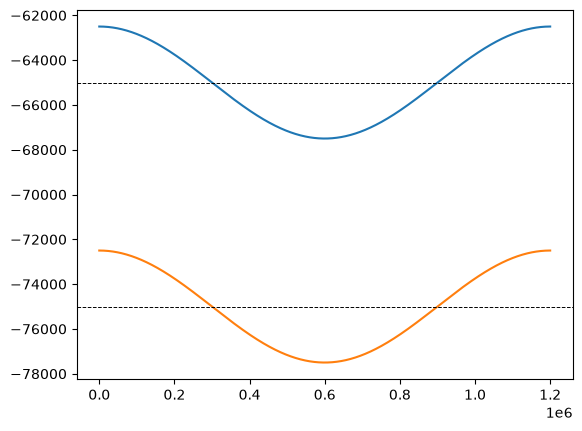

In [6]:
# layers thickness
t_air = 40.0e3 #m
t_top = 2.0e3 #m
t_uc = 23.0e3 #m
t_lc = 10.0e3 #m
t_litho = 120.0e3 #m

# layers depth
d_top = -(t_air) # crust top
d_uc = -(t_top+t_air) # just to paint the top of the basement
d_lc = -(t_top+t_uc+t_air) # upper crust base
d_lm = -(t_top+t_uc+t_lc+t_air) # lower crust base
d_ast = -(t_litho+t_air) # lithosphere base

dh = 2.5e3
xi = np.linspace(0, lx, nx)
surf_sin = dh*np.sin((xi * 2*np.pi)/lx - np.pi/2)

surf_lc = np.ones_like(xi)*d_lc - surf_sin
surf_lm = np.ones_like(xi)*d_lm - surf_sin 

plt.plot(xi,surf_lc)
plt.plot(xi,surf_lm)
plt.axhline(y=d_lc, color='k', linestyle='--',lw=0.7)
plt.axhline(y=d_lm, color='k', linestyle='--',lw=0.7)
# #weak seed position
# x_ws = int(lx/3)
# d_ws = d_lm - 13.0e3 # 13 km under the lithospheric mantle
# t_ws = 6.0e3
# l_ws = 6.0e3

# ws_poly = Polygon(
#                   [(x_ws-l_ws/2,d_ws+t_ws/2), # 1       1------2
#                    (x_ws+l_ws/2,d_ws+t_ws/2), # 2       |      |
#                    (x_ws+l_ws/2,d_ws-t_ws/2), # 3       |      |
#                    (x_ws-l_ws/2,d_ws-t_ws/2)] # 4       4------3
#                    )


In [7]:
p_uc =  DEFAULT_MATERIALS['WET_QUARTZ'].copy()
p_uc['H']=4.8e-10 # W/kg
p_uc['friction_angle_max'] = 20.0
p_uc['friction_angle_min'] = 5.0
p_uc['cohesion_min'] = 1.0e6 # Pa

p_top = p_uc.copy()


p_lc = DEFAULT_MATERIALS['WET_ANORTHITE'].copy()
p_lc['rho'] = 2800.0
p_lc['C'] = C_lc
p_lc['friction_angle_max'] = 20.0
p_lc['friction_angle_min'] = 5.0
p_lc['cohesion_min'] = 5.0e6 # Pa

p_sed = DEFAULT_MATERIALS['WET_QUARTZ'].copy()
p_sed['rho'] = 2400.0 # kg/m3
p_sed['friction_angle_min'] = 5.0
p_sed['cohesion_min'] = 5.0e6 # Pa
p_sed['cohesion_max'] = 10.0e6 # Pa
p_sed['H'] = 5.417e-10 # W/kg
p_sed['k'] = 0.7e-6

p_lm = DEFAULT_MATERIALS['DRY_OLIVINE'].copy()
p_ast = DEFAULT_MATERIALS['WET_OLIVINE'].copy()

p_lm['k'] = p_ast['k'] = 1.2e-6
p_lm['friction_angle_max'] = p_ast['friction_angle_max'] = 20.0
p_lm['friction_angle_min'] = p_ast['friction_angle_min'] = 5.0
p_lm['cohesion_min'] = p_ast['cohesion_min'] = 5e6

p_air = DEFAULT_MATERIALS['AIR'].copy()
p_water = DEFAULT_MATERIALS['AIR'].copy()
p_water['rho'] = 1000.0

In [9]:
sed_times = []
sed_layer = []

In [10]:
scen.create_interface(0,d_ast,interface_name='asthenosphere',**p_ast)
scen.create_interface(1,surf_lm, interface_name='lithospheric_mantle',**p_lm)
scen.create_interface(2,surf_lc, interface_name='lower_crust',**p_lc)
scen.create_interface(3,d_uc, interface_name='upper_crust',**p_uc)
scen.create_interface(4,d_top, interface_name='basement',**p_uc)

# add syn-rift sediments
index_i = len(scen.DTree.interfaces)
t_i = 0.0
dt = 1.0
t_max = 70

for i in np.arange(t_i,t_max,dt):
    scen.create_interface(index_i,d_top, interface_name=f'sed_{i:.1f}',**p_sed)
    sed_times.append(i)
    sed_layer.append(index_i)
    index_i += 1

scen.create_interface(index_i,d_top, interface_name=f'water',**p_water)
scen.create_interface(-1, 0.0, interface_name='air',**p_air)

ID 0 -> asthenosphere
C:1.0; rho:3378.0; H:0.0; A:1.393e-14; n:3.0; Q:429000.0; V:1.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a flat line/surface
ID 1 -> lithospheric_mantle
C:1.0; rho:3354.0; H:9e-12; A:2.417e-15; n:3.5; Q:540000.0; V:2.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
The whole interfaces was provided, no need to interpolate
ID 2 -> lower_crust
C:0.5; rho:2800.0; H:7.123e-11; A:3.9810717e-16; n:3.0; Q:356000.0; V:0.0; k:1.15e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:25000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
The whole interfaces was provided, no need to interpolate
ID 3 -> upper_crust
C:1.0; rho:2700.0; H:4.8e-10; A:8.574e-28; n:4.0; Q:222000.0; V:0.0; k:1e-06; weakening_seed:-1.0;

In [11]:
scen.DTree

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:  (x: 1201, z: 401)
│       Coordinates:
│         * x        (x) float64 10kB 0.0 1e+03 2e+03 ... 1.198e+06 1.199e+06 1.2e+06
│         * z        (z) float64 3kB -4e+05 -3.99e+05 -3.98e+05 ... -2e+03 -1e+03 0.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1201)
        Coordinates:
          * x                    (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
        Data variables: (12/77)
            asthenosphere        (x) float64 10kB -1.6e+05 -1.6e+05 ... -1.6e+05
            lithospheric_mantle  (x) float64 10kB -7.25e+04 -7.25e+04 ... -7.25e+04
            lower_crust          (x) float64 10kB -6.25e+04 -6.25e+04 ... -6.25e+04
            upper_crust          (x) float64 10kB -4.2e+04 -4.2e+04 ... -4.2e+04
            basement             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_0.0              (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            ...                   ...
            sed_66.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_67.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_68.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_69.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            water                (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            air                  (x) float64 10kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

In [12]:
scen.create_materials_fields()

Sorting interfaces by ID:
air-asthenosphere-lithospheric_mantle-lower_crust-upper_crust-basement-sed_0.0-sed_1.0-sed_2.0-sed_3.0-sed_4.0-sed_5.0-sed_6.0-sed_7.0-sed_8.0-sed_9.0-sed_10.0-sed_11.0-sed_12.0-sed_13.0-sed_14.0-sed_15.0-sed_16.0-sed_17.0-sed_18.0-sed_19.0-sed_20.0-sed_21.0-sed_22.0-sed_23.0-sed_24.0-sed_25.0-sed_26.0-sed_27.0-sed_28.0-sed_29.0-sed_30.0-sed_31.0-sed_32.0-sed_33.0-sed_34.0-sed_35.0-sed_36.0-sed_37.0-sed_38.0-sed_39.0-sed_40.0-sed_41.0-sed_42.0-sed_43.0-sed_44.0-sed_45.0-sed_46.0-sed_47.0-sed_48.0-sed_49.0-sed_50.0-sed_51.0-sed_52.0-sed_53.0-sed_54.0-sed_55.0-sed_56.0-sed_57.0-sed_58.0-sed_59.0-sed_60.0-sed_61.0-sed_62.0-sed_63.0-sed_64.0-sed_65.0-sed_66.0-sed_67.0-sed_68.0-sed_69.0-water
Field created: density [kg/m3]
Field created: scale_factor [dimensionless]
Field created: radiogenic_heat [W/kg]
Field created: pre-exponential_scale_factor [Pa^(-n)/s]
Field created: power_law_exponent [dimensionless]
Field created: activation_energy [J/mol]
Field created: ac

(-400000.0, 0.0)

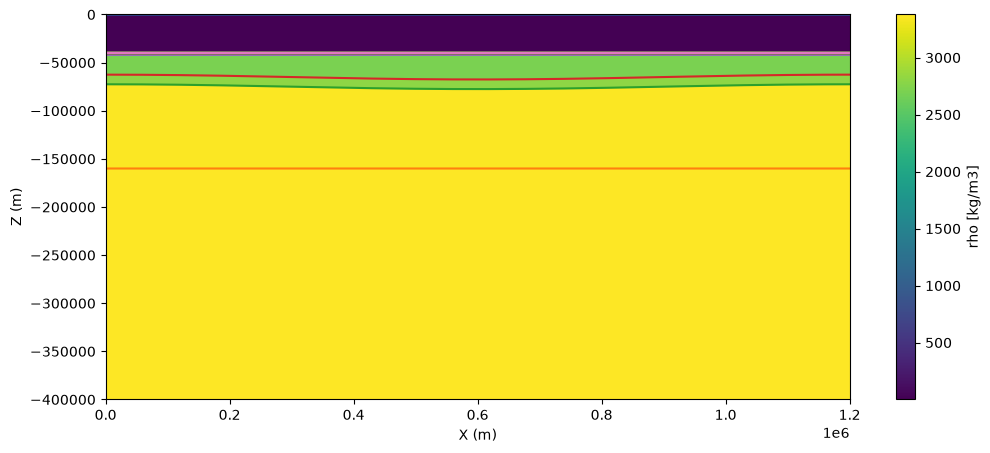

In [13]:
plt.figure(figsize=(12,5))

scen.DTree.fields.rho.plot.pcolormesh(x='x')
for ds in scen.DTree.interfaces.values():
    ds.plot(x='x',label=f'({ds.attrs["id"]:02d}) {ds.name}')


plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.xlim(0,scen.Lx)
plt.ylim(scen.Lz,0)

Velocity is given in cm/y. The field will be automatically converted to m/s
The velocity builder was created.
(set) velocity in the right: from [-180000.0,-30000.0], vx=7.500e-01, vz=0.000e+00 cm/y
Int V = 3.589e-05 m²/s
v_ast = -2.0083 cm/y
linear velocity in the right boundary: vx = 1.254e-05 * COORD + 3.007e+00
(set) velocity in the left: from [-180000.0,-30000.0], vx=-7.500e-01, vz=0.000e+00 cm/y
linear velocity in the left boundary: vx = -1.254e-05 * COORD + -3.007e+00
Int V = -1.619e-05 m²/s
(add) velocity in the top: from [1500.0,1198500.0], vx=0.000e+00, vz=2.134e-02 cm/y
Int V = -8.094e-06 m²/s
(add) velocity in the bot: from [1500.0,1198500.0], vx=0.000e+00, vz=-1.067e-02 cm/y
Int V = -4.047e-06 m²/s
(add) velocity in the top: from [1500.0,1198500.0], vx=0.000e+00, vz=5.335e-03 cm/y
Int V = -2.023e-06 m²/s
(add) velocity in the bot: from [1500.0,1198500.0], vx=0.000e+00, vz=-2.667e-03 cm/y
Int V = -1.012e-06 m²/s
(add) velocity in the top: from [1500.0,1198500.0], vx=0.000e+0

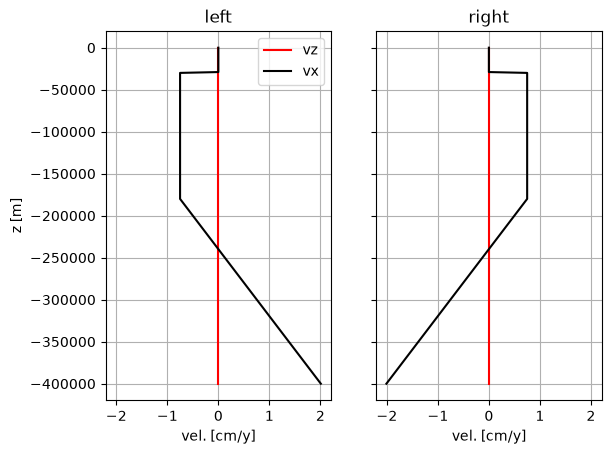

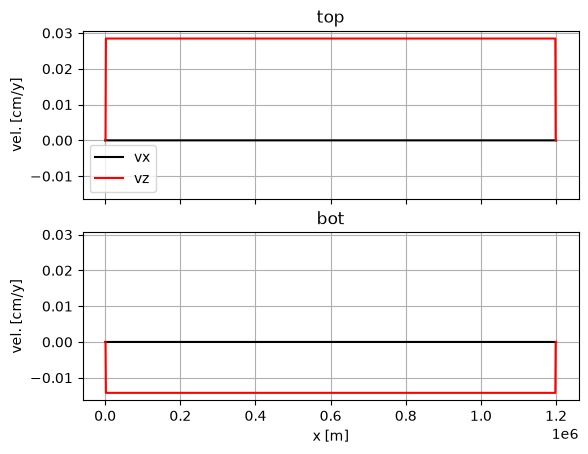

In [14]:
ast_range = 20e3 #m
air_range = 10e3 #m

# creating the velocity builder
velocbuild = VelocityFieldBuilder(scen)

# constant velocity in the lithosphere
velocbuild.set_region('right',[(d_ast-ast_range),(d_top+air_range)],vx=v_rift, vz=0) # constant velocity in the right


int_out = velocbuild.integrate_normal_components()*velocbuild.unifac_int # integral of outflux cm²/y 
in_range = ((d_ast-ast_range)-(-lz+t_air))*100 # cm

v_ast = (-2*int_out / in_range)-v_rift  # asthenospheric normal velocity in z=Lz
print(f'v_ast = {v_ast:.4f} cm/y')

velocbuild.linear_velocity('right','vx',range=[scen.Lz,(d_ast-ast_range)],
                           clims=[scen.Lz,(d_ast-ast_range)],
                           vlims=[v_ast,v_rift])


velocbuild.set_region('left',[(d_ast-ast_range),(d_top+air_range)],vx=-v_rift, vz=0) # constant velocity in the left
velocbuild.linear_velocity('left','vx',range=[scen.Lz,(d_ast-ast_range)],
                           clims=[scen.Lz,(d_ast-ast_range)],
                           vlims=[-v_ast,-v_rift])


# keeping the velocity field conservative
for i in range(10):
    velocbuild.conservate_veloc('top',0.5)
    velocbuild.conservate_veloc('bot',0.5)

lr, bt = velocbuild.view_veloc()
lr.savefig(os.path.join(scen.path,'v_lr.png'),bbox_inches='tight')
bt.savefig(os.path.join(scen.path,'v_bt.png'),bbox_inches='tight')

scen.create_velocity_field(velocbuild)

In [15]:
scen.DTree

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:             (z: 401, x: 1201)
│       Coordinates:
│         * z                   (z) float64 3kB -4e+05 -3.99e+05 ... -1e+03 0.0
│         * x                   (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
│       Data variables: (12/15)
│           rho                 (z, x) float64 4MB 3.378e+03 3.378e+03 ... 1.0 1.0
│           C                   (z, x) float64 4MB 1.0 1.0 1.0 1.0 ... 0.1 0.1 0.1 0.1
│           H                   (z, x) float64 4MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
│           A                   (z, x) float64 4MB 1.393e-14 1.393e-14 ... 1e-18 1e-18
│           n                   (z, x) float64 4MB 3.0 3.0 3.0 3.0 ... 1.0 1.0 1.0 1.0
│           Q                   (z, x) float64 4MB 4.29e+05 4.29e+05 ... 0.0 0.0
│           ...                  ...
│           cohesion_min        (z, x) float64 4MB 5e+06 5e+06 5e+06 ... 1e+05 1e+05
│           cohesion_max        (z, x) float64 4MB 2e+07 2e+07 2e+07 ... 1e+06 1e+06
│           friction_angle_min  (z, x) float64 4MB 5.0 5.0 5.0 5.0 ... 2.0 2.0 2.0 2.0
│           friction_angle_max  (z, x) float64 4MB 20.0 20.0 20.0 20.0 ... 5.0 5.0 5.0
│           vx                  (z, x) float64 4MB 6.364e-10 0.0 0.0 0.0 ... 0.0 0.0 0.0
│           vz                  (z, x) float64 4MB 0.0 0.0 -4.508e-12 ... 0.0 0.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1201)
        Coordinates:
          * x                    (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
        Data variables: (12/77)
            air                  (x) float64 10kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
            asthenosphere        (x) float64 10kB -1.6e+05 -1.6e+05 ... -1.6e+05
            lithospheric_mantle  (x) float64 10kB -7.25e+04 -7.25e+04 ... -7.25e+04
            lower_crust          (x) float64 10kB -6.25e+04 -6.25e+04 ... -6.25e+04
            upper_crust          (x) float64 10kB -4.2e+04 -4.2e+04 ... -4.2e+04
            basement             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            ...                   ...
            sed_65.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_66.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_67.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_68.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_69.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            water                (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

In [16]:
tempbuild_bound = TemperatureFieldBuilder(scen,c_cap=1250,g=-10,alpha = 0.0000328)
tempbuild_bound.apply_basic_temperature(lithosphere_thickness=t_litho,t_pot=1350)
tempbuild_bound.solve_heat_diffusion1D(500e6, 5e3, x_inx=1)

Running 100000 iterations for 1D profile...
using dt = 1.57e+03 yrs (dt_max is 1.58e+03).
318763 steps to run.


In [17]:
tempbuild_center = TemperatureFieldBuilder(scen,c_cap=1250,g=-10,alpha = 0.0000328)
tempbuild_center.apply_basic_temperature(lithosphere_thickness=t_litho,t_pot=1350)
tempbuild_center.solve_heat_diffusion1D(500e6, 5e3, x_inx=601)

Running 100000 iterations for 1D profile...
using dt = 1.57e+03 yrs (dt_max is 1.58e+03).
318763 steps to run.


In [18]:
cthres = 200e3
c = lx/2
tbd = tempbuild_bound.temperature
tct = tempbuild_center.temperature
tempfield = xr.where((tct.x > c - cthres) & (tct.x < c + cthres), tct, tbd)

In [19]:
import scipy.ndimage as ndimage

tempfield_filtered = xr.apply_ufunc(
    ndimage.gaussian_filter1d,
    tempfield,  # your xarray DataArray
    kwargs={"sigma": 10.0, "order": 0},
    input_core_dims=[["x"]],   # Apply the function along the 'x' dimension
    output_core_dims=[["x"]],  # The function returns an array with the 'x' dimension
    vectorize=True,            # Automatically loops over the 'time' dimension
)

In [20]:
tempbuild = TemperatureFieldBuilder(scen,c_cap=1250,g=-10,alpha = 0.0000328)
tempbuild.apply_basic_temperature(lithosphere_thickness=t_litho,t_pot=1350)
tempbuild.temperature = tempfield_filtered

/home/jobueno/miniconda3/envs/tapioca/lib/python3.14/site-packages/IPython/core/events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


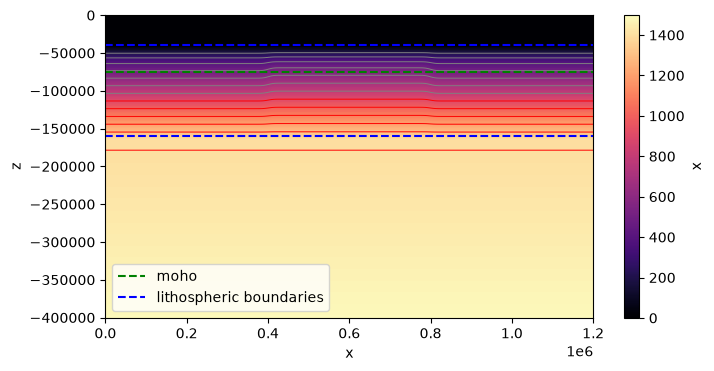

In [21]:
plt.figure(figsize=(20,10,'cm'))
tempbuild.temperature.plot(y='z',vmin=0,vmax=1500,cmap='magma')
tempbuild.temperature.plot.contour(y='z',colors='gray',levels=np.arange(200,801,100),lw=0.7)
tempbuild.temperature.plot.contour(y='z',colors='red',levels=np.arange(900,1600,100),lw=0.7)

plt.axhline(d_top,color='blue',ls='--',lw=1.5)
plt.axhline(d_lm,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_ast,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')
plt.legend()

In [22]:
scen.create_temperature_field(tempbuild)

Temperature field was created in the scenario builder.


In [23]:
scen.calculate_YSE(sr=1e-15)
# np.log10(scen.DTree.fields.viscous_YSE/1e-15).plot(vmin=18,vmax=25)

Using thermal expansion coefficient used in the `TemperatureFieldBuilder`: alpha=3.28e-05
Lithostatic pressure was calculated.
Plastic rheology: Druker-Prager Criterion
Viscous rheology: dislocation creep
Yield Strength Envelopte was calculated.


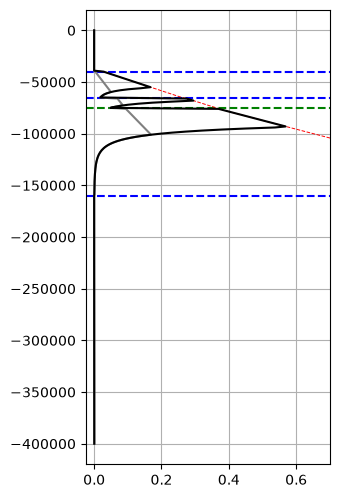

In [24]:
plt.figure(figsize=(8,15,'cm'))

plt.axhline(d_top,color='blue',ls='--',lw=1.5)
plt.axhline(d_lc,color='blue',ls='--',lw=1.5)
plt.axhline(d_lm,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_ast,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')

plt.plot(scen.DTree.fields.plastic_YSE[:,301]/1e9, scen.DTree.fields.z, color='red',ls='--',lw=0.7)
plt.plot(scen.DTree.fields.YSE_soft[:,301]/1e9,scen.DTree.fields.z,color='gray')
plt.plot(scen.DTree.fields.YSE[:,301]/1e9,scen.DTree.fields.z,color='black')

plt.xlim(-0.025,0.7)
plt.grid()

In [25]:
colors = {'air':"#ffffff",
 'asthenosphere':"#81a75e",
 'lithospheric_mantle':"#587240",
 'lower_crust':"#c2a886",
 'upper_crust':"#717ea1",
 'basement':"#00025F"}

colors['bot_weak_seed'] = colors['lithospheric_mantle']
colors['top_weak_seed'] = "#1C2414"

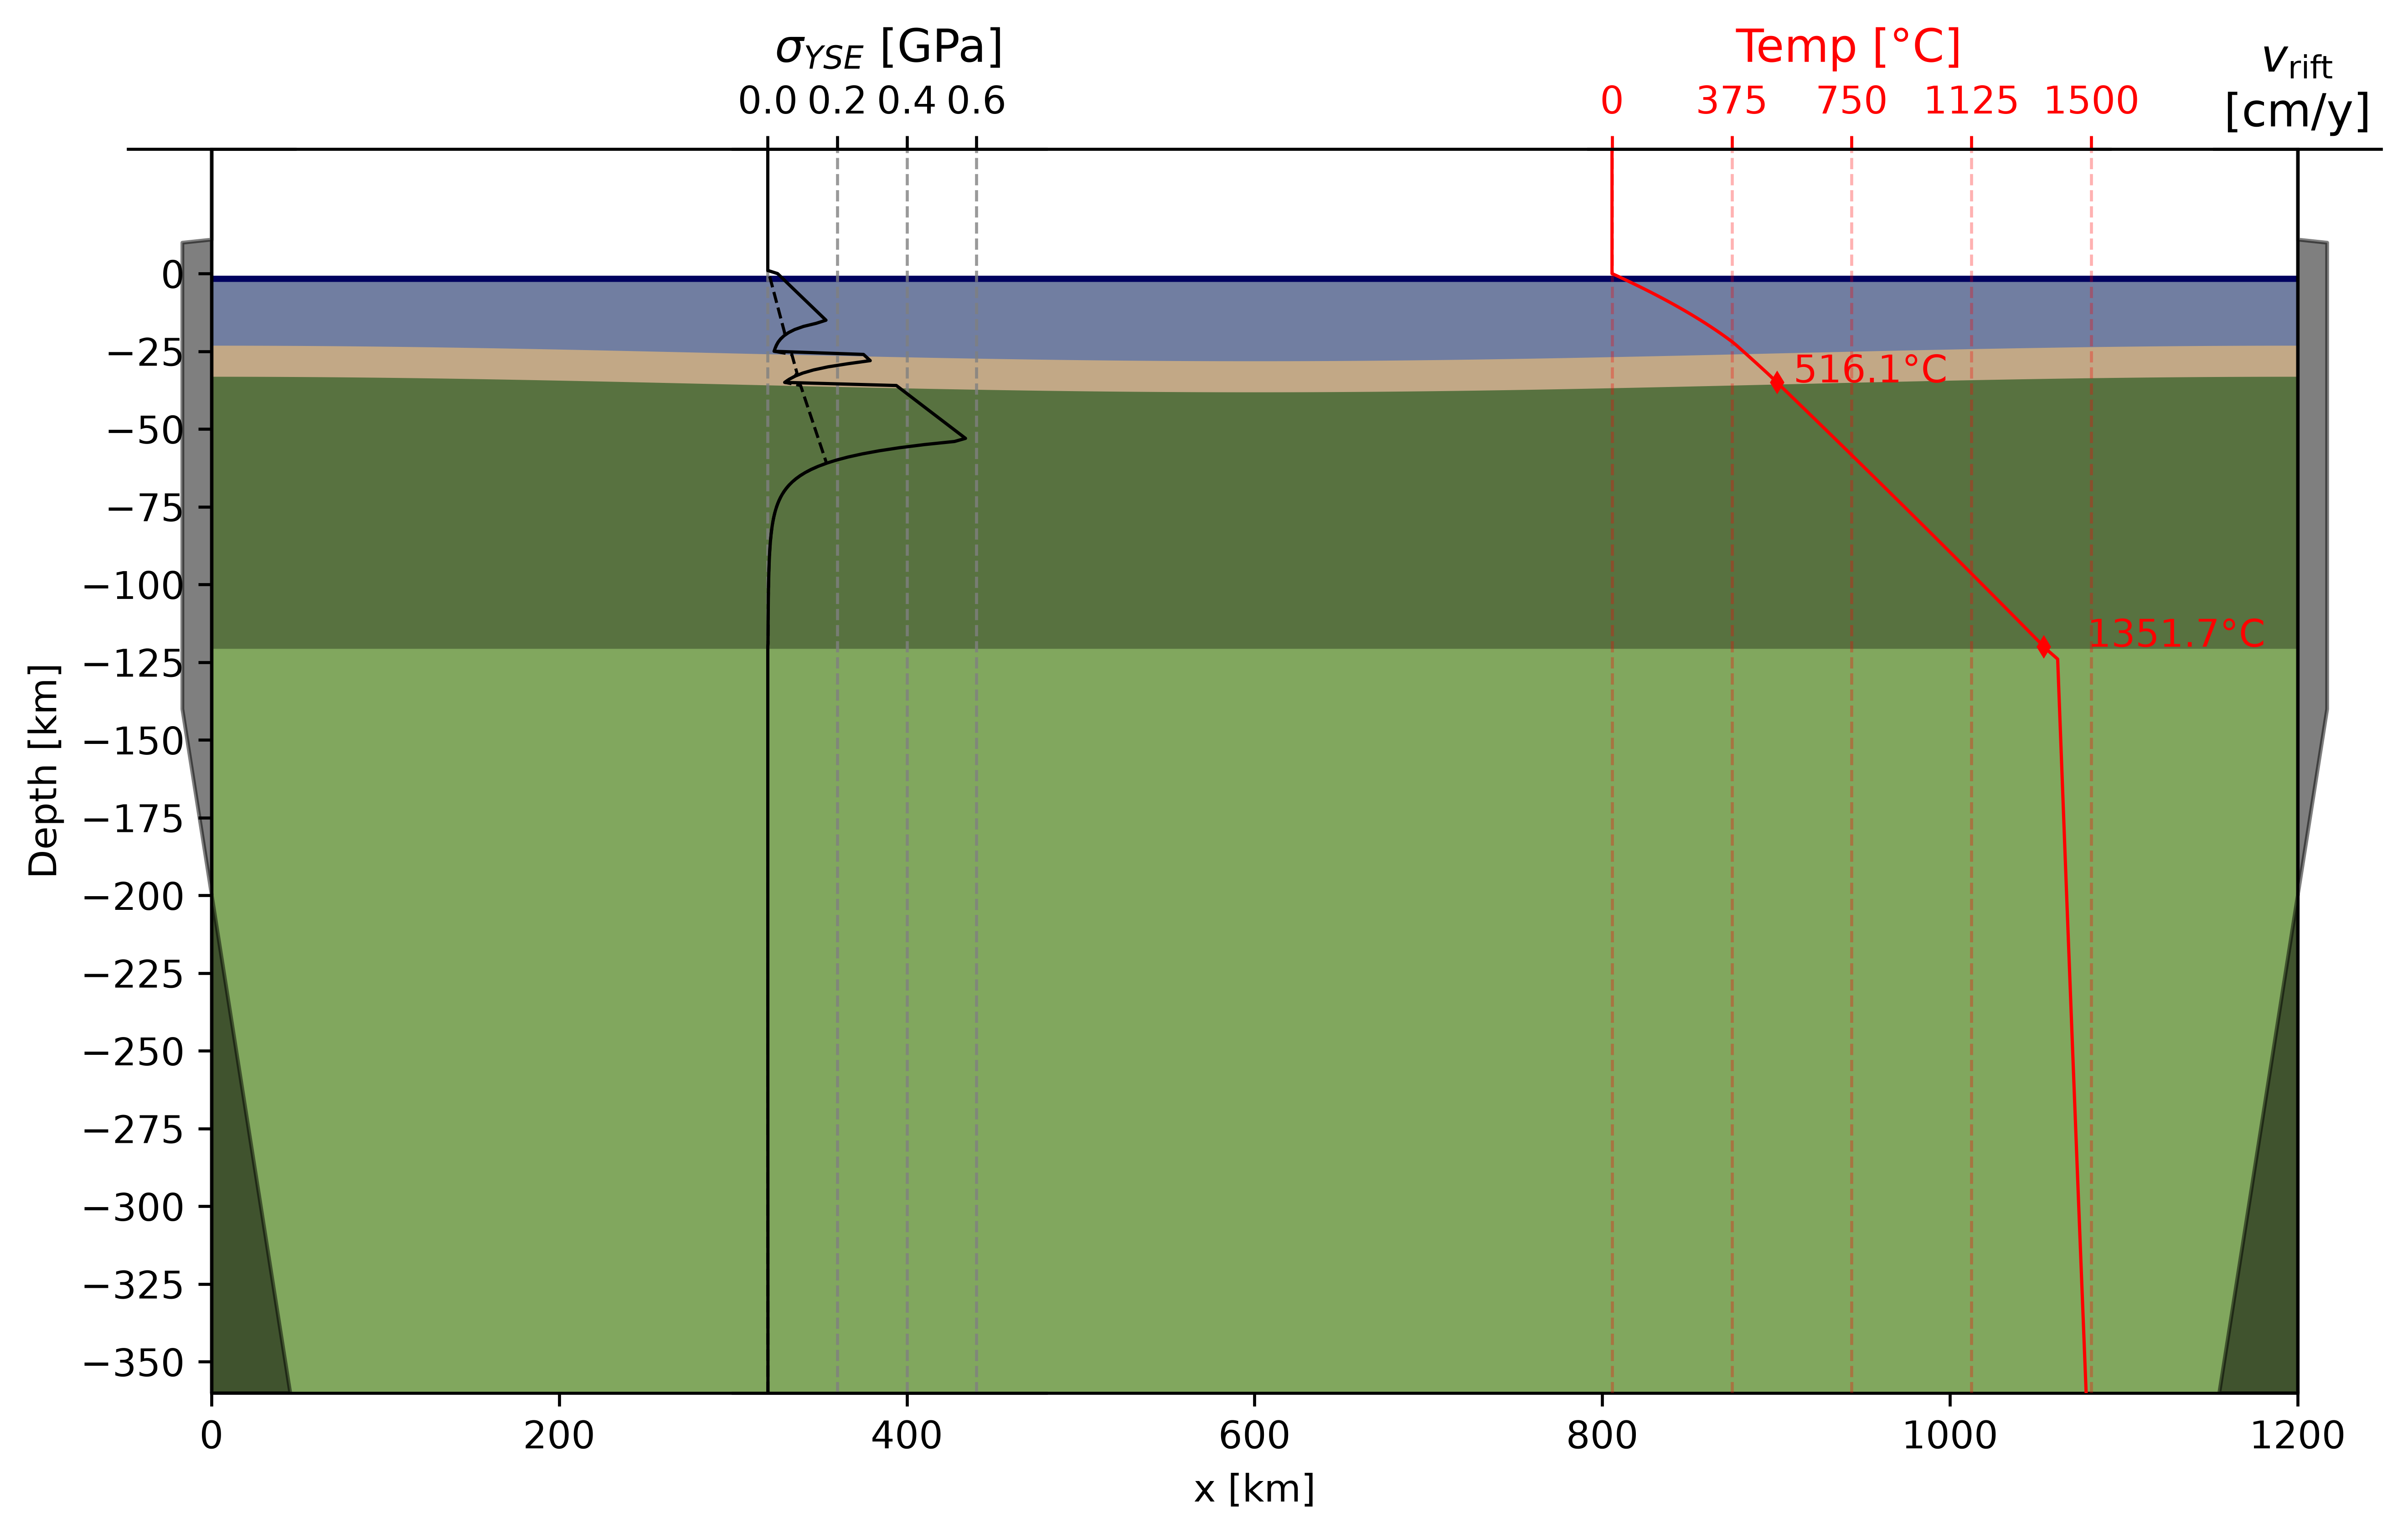

In [26]:
fig, ax = plt.subplots(figsize=(25, 15,'cm'),dpi=600)
ylimplot = [(-lz+t_air)/1e3, (0 + t_air)/1e3]

inx_profiles = 301

interfaces = scen.DTree.interfaces
interfaces_list = list(interfaces.data_vars)

xplot = scen.DTree.fields.x/1e3
zplot = (scen.DTree.fields.z+t_air)/1e3

#asthenosphere
ax.fill_between(xplot, (-lz + t_air)/1e3, 
                (interfaces[interfaces_list[1]].values+ t_air)/1e3, 
                color=colors.get('asthenosphere',None),label='asthenosphere')

for i in range(2,len(interfaces_list)):
    ci_name = interfaces_list[i]
    pi_name = interfaces_list[i-1]

    cint = interfaces[ci_name].values + t_air
    pint = interfaces[pi_name].values + t_air
    
    ax.fill_between(xplot, cint/1e3, pint/1e3, color=colors.get(ci_name,None),label=ci_name)#.get(label,None))

#air
ax.fill_between(xplot, (interfaces[interfaces_list[-1]].values+ t_air)/1e3, 
                (interfaces[interfaces_list[0]].values+ t_air)/1e3, 
                color=colors.get('air',None),label='air')


ax.set_yticks(np.arange(-lz/1e3, 1, 25))

ax.set_xlim([0, lx/1e3])
ax.set_ylim(ylimplot)

ax.set_xlabel("x [km]")
ax.set_ylabel("Depth [km]")

# plt.title("Interfaces")

MS_CMY = 100*365.25*24*3600

velx = scen.DTree.fields.vx
fac = 0.96
# Velocity = Right side
vr = velx.isel(x=-1)
vr_plot = np.max(abs(vr))*MS_CMY + 0.125

axr = ax.inset_axes((fac,0,(1-fac)*2,1))
axr.fill_betweenx(zplot, vr*MS_CMY, 0, color='k', facecolor='k', hatch=None,alpha=0.5)
axr.set_ylim(ylimplot)
axr.set_yticks([])
axr.set_xticks([])
axr.patch.set_alpha(0)
axr.xaxis.set_ticks_position('top')
axr.tick_params(labelbottom=False,labeltop=True)
axr.set_xlim([-vr_plot,vr_plot])
axr.spines['left'].set_visible(False)
axr.spines['right'].set_visible(False)
axr.spines['bottom'].set_visible(False)
axr.set_title("$v_{\\text{rift}}$\n[cm/y]")

# Velocity = Left side
vl = velx.isel(x=0)
vl_plot = np.max(abs(vl))*MS_CMY + 0.125

axl = ax.inset_axes((-(1-fac),0,(1-fac)*2,1))
axl.fill_betweenx(zplot, 0, vl*MS_CMY, color='k', facecolor='k', hatch=None,alpha=0.5)
axl.set_ylim(ylimplot)
axl.set_yticks([])
axl.set_xticks([])
axl.patch.set_alpha(0)
axl.xaxis.set_ticks_position('top')
axl.tick_params(labelbottom=False,labeltop=True)
axl.set_xlim([-vl_plot, vl_plot])
axl.spines['left'].set_visible(False)
axl.spines['right'].set_visible(False)
axl.spines['bottom'].set_visible(False)

# Temperature
temp_prof = scen.DTree.fields.temperature.isel(x=inx_profiles)
T_moho = temp_prof.interp(z=d_lm)
T_lab = temp_prof.interp(z=d_ast)

axt = ax.inset_axes((3.3/5,0,0.25,1))
axt.plot(temp_prof.values, zplot, "-r",lw=0.85)
axt.grid(visible=True, axis='x',which='both',ls='--',color='red',alpha=0.3)
axt.set_ylim(ylimplot)
axt.set_yticks([])
axt.set_xticks(np.linspace(0,1500,5))
axt.patch.set_alpha(0)
axt.xaxis.set_ticks_position('top')
axt.set_yticks([])
axt.xaxis.label.set_color('red')
axt.tick_params(axis='x', colors='red')
axt.spines['left'].set_visible(False)
axt.spines['right'].set_visible(False)
axt.set_title('Temp [°C]',color='red')
axt.spines['bottom'].set_visible(False)

# Marker in the Moho
axt.plot(T_moho,(d_lm+t_air)/1e3,'rd',ms=3.0) 
axt.annotate(f'{T_moho:.1f}°C',(T_moho*1.1,(d_lm+t_air)/1e3),color='red')

# Marker in the Moho
axt.plot(T_lab,(d_ast+t_air)/1e3,'rd',ms=3.0) 
axt.annotate(f'{T_lab:.1f}°C',(T_lab*1.1,(d_ast+t_air)/1e3),color='red')

# #yield strength envelope
YSE = scen.DTree.fields.YSE.isel(x=inx_profiles) /1e9 #GPa
YSE_soft = scen.DTree.fields.YSE_soft.isel(x=inx_profiles) /1e9 #GPa

axsg = ax.inset_axes((300/1200,0,0.15,1))
axsg.plot(YSE_soft,zplot,'k--',lw=0.8)
axsg.plot(YSE,zplot,'k',lw=0.85)

axsg.grid(visible=True, axis='x',which='both',ls='--',color='gray',alpha=0.8)
axsg.set_xticks([0,0.2,0.4,0.6])
axsg.set_xlim(-0.1,0.8)
axsg.set_ylim(ylimplot)
axsg.set_yticks([])
axsg.patch.set_alpha(0)
axsg.xaxis.set_ticks_position('top')
axsg.spines['left'].set_visible(False)
axsg.spines['right'].set_visible(False)
axsg.set_title('$\\sigma_{YSE}$ [GPa]')
    
# plt.legend(bbox_to_anchor=(0., -.31, 1., -.102), loc='lower left', ncols=3, mode="expand", borderaxespad=0.,shadow=True)

# #fig.legend(ncols=3,mode='expand',bbox_to_anchor=(0., -0.1), borderaxespad=0.)
# plt.tight_layout()
# plt.show()
fig.savefig(os.path.join(scen.path,f'interfaces.svg'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(scen.path,f'interfaces.png'),dpi=300,bbox_inches='tight')

In [27]:
scen.DTree

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:             (z: 401, x: 1201)
│       Coordinates:
│         * z                   (z) float64 3kB -4e+05 -3.99e+05 ... -1e+03 0.0
│         * x                   (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
│       Data variables: (12/23)
│           rho                 (z, x) float64 4MB 3.378e+03 3.378e+03 ... 1.0 1.0
│           C                   (z, x) float64 4MB 1.0 1.0 1.0 1.0 ... 0.1 0.1 0.1 0.1
│           H                   (z, x) float64 4MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
│           A                   (z, x) float64 4MB 1.393e-14 1.393e-14 ... 1e-18 1e-18
│           n                   (z, x) float64 4MB 3.0 3.0 3.0 3.0 ... 1.0 1.0 1.0 1.0
│           Q                   (z, x) float64 4MB 4.29e+05 4.29e+05 ... 0.0 0.0
│           ...                  ...
│           litho_P             (z, x) float64 4MB 1.244e+10 1.244e+10 ... 1e+04 1e+04
│           plastic_YSE         (z, x) float64 4MB 4.274e+09 4.274e+09 ... 9.971e+05
│           plastic_YSE_soft    (z, x) float64 4MB 1.089e+09 1.089e+09 ... 1.003e+05
│           viscous_YSE         (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│           YSE                 (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│           YSE_soft            (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1201)
        Coordinates:
          * x                    (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
        Data variables: (12/77)
            air                  (x) float64 10kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
            asthenosphere        (x) float64 10kB -1.6e+05 -1.6e+05 ... -1.6e+05
            lithospheric_mantle  (x) float64 10kB -7.25e+04 -7.25e+04 ... -7.25e+04
            lower_crust          (x) float64 10kB -6.25e+04 -6.25e+04 ... -6.25e+04
            upper_crust          (x) float64 10kB -4.2e+04 -4.2e+04 ... -4.2e+04
            basement             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            ...                   ...
            sed_65.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_66.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_67.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_68.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_69.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            water                (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

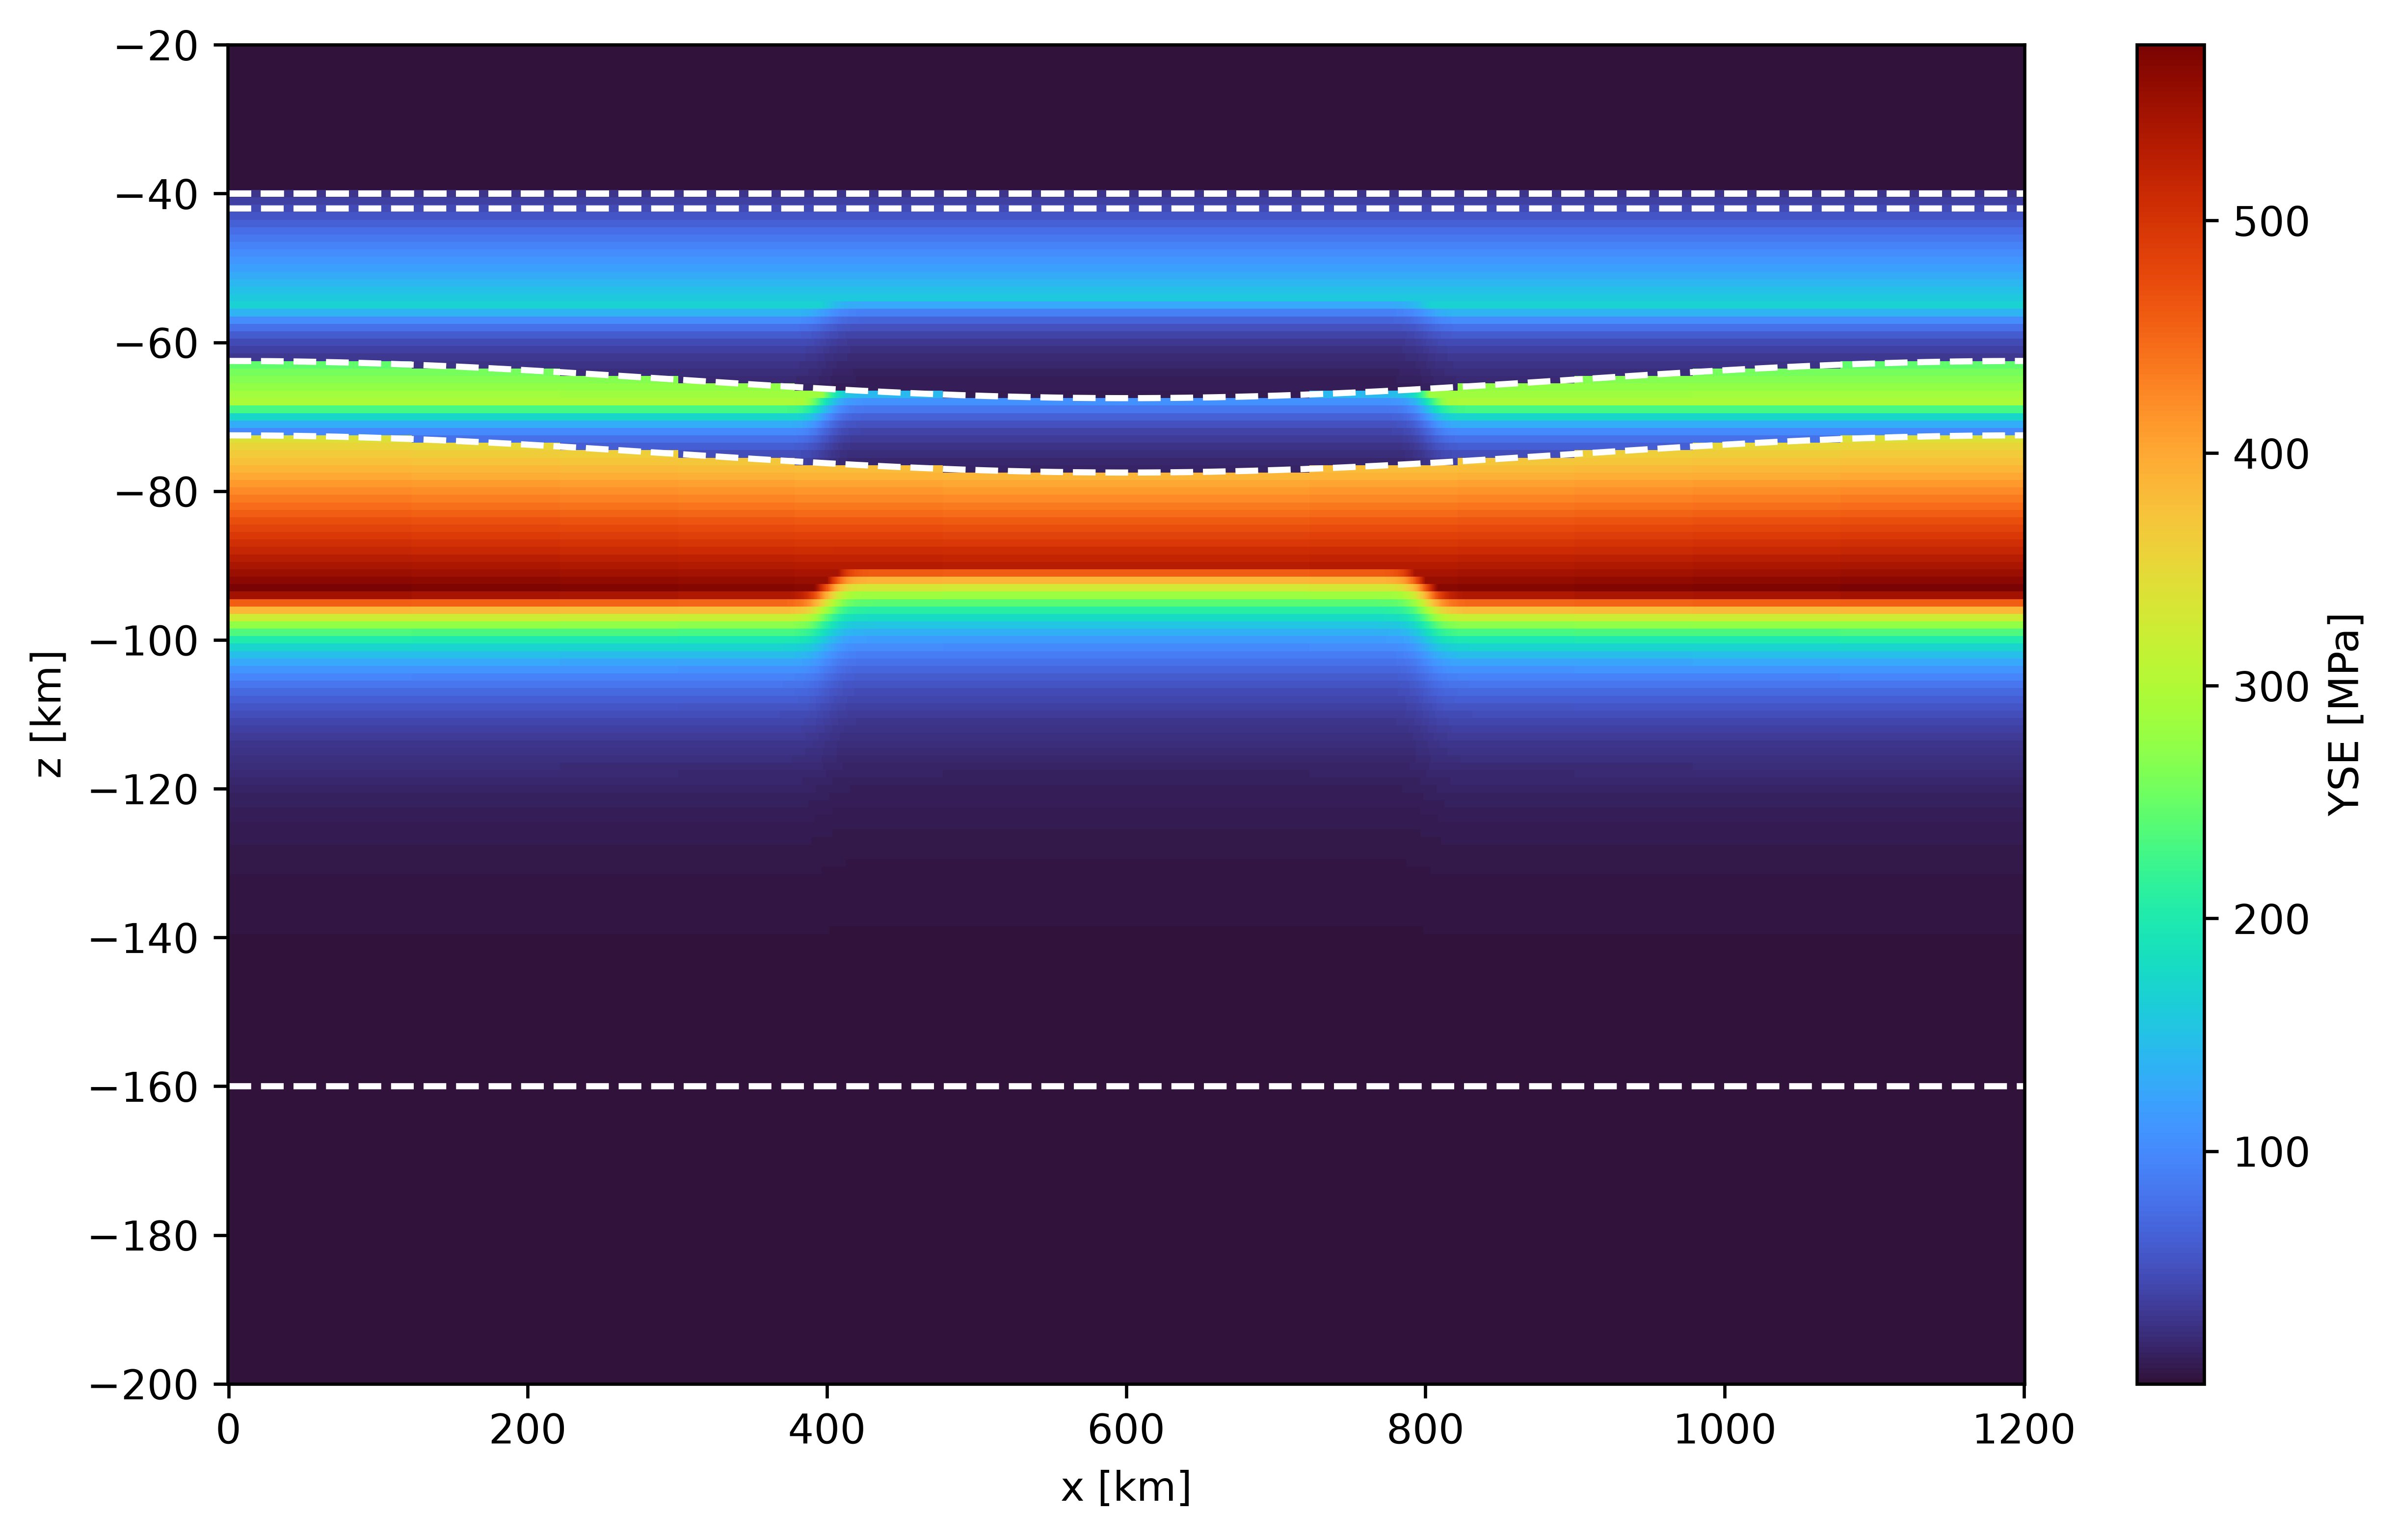

In [28]:
yse_field = scen.DTree.fields.YSE/1e6

fig, ax = plt.subplots(figsize=(25, 15,'cm'),dpi=600)
yseplot = ax.pcolormesh(scen.DTree.fields.x/1e3,scen.DTree.fields.z/1e3,yse_field, cmap='turbo',rasterized=True)

for ds in scen.DTree.interfaces.values():
    ax.plot(ds.x/1e3, ds.values/1e3,label=f'({ds.name}',color='white',ls='--')

fig.colorbar(yseplot,label='YSE [MPa]')

ax.set_ylabel('z [km]')
ax.set_xlabel('x [km]')
ax.set_ylim(-200,-20)

fig.savefig(os.path.join(scen.path,f'YSE_field.svg'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(scen.path,f'YSE_field.png'),dpi=300,bbox_inches='tight')

In [27]:
scen.export_interfaces(export='csv')
scen.export_field('velocity')
scen.export_field('temperature')

Exporting dataset to interfaces.txt
Interfaces: asthenosphere -> lithospheric_mantle -> lower_crust -> upper_crust -> basement -> sed_0.0 -> sed_1.0 -> sed_2.0 -> sed_3.0 -> sed_4.0 -> sed_5.0 -> sed_6.0 -> sed_7.0 -> sed_8.0 -> sed_9.0 -> sed_10.0 -> sed_11.0 -> sed_12.0 -> sed_13.0 -> sed_14.0 -> sed_15.0 -> sed_16.0 -> sed_17.0 -> sed_18.0 -> sed_19.0 -> sed_20.0 -> sed_21.0 -> sed_22.0 -> sed_23.0 -> sed_24.0 -> sed_25.0 -> sed_26.0 -> sed_27.0 -> sed_28.0 -> sed_29.0 -> sed_30.0 -> sed_31.0 -> sed_32.0 -> sed_33.0 -> sed_34.0 -> sed_35.0 -> sed_36.0 -> sed_37.0 -> sed_38.0 -> sed_39.0 -> sed_40.0 -> sed_41.0 -> sed_42.0 -> sed_43.0 -> sed_44.0 -> sed_45.0 -> sed_46.0 -> sed_47.0 -> sed_48.0 -> sed_49.0 -> sed_50.0 -> sed_51.0 -> sed_52.0 -> sed_53.0 -> sed_54.0 -> sed_55.0 -> sed_56.0 -> sed_57.0 -> sed_58.0 -> sed_59.0 -> sed_60.0 -> sed_61.0 -> sed_62.0 -> sed_63.0 -> sed_64.0 -> sed_65.0 -> sed_66.0 -> sed_67.0 -> sed_68.0 -> sed_69.0 -> water -> air
16
Exporting interfaces to 

In [28]:
base_levels = [[0.00,-500],
               [t_max,-500]
          ]
with open(os.path.join(scen.path,"base_level.txt"), "w") as f:
    np.savetxt(f, base_levels, fmt="%.2f %.0f", delimiter=" ")

In [29]:
sed_rates = np.full_like(sed_times,sed_rate)
Lds = np.full_like(sed_times,Ld)
SP_vc_array = np.array([sed_times,sed_layer,sed_rates,Lds]).T

# TIME LAYER RATE LD 
with open(os.path.join(scen.path,"SP_vc.txt"), "w") as f:
    np.savetxt(f, SP_vc_array, fmt="%.2f %d %.2f %.1f", delimiter=" ")

In [30]:
n_interfaces = len(scen.DTree.interfaces)-1
id_water = scen.DTree.interfaces['water'].attrs['id']
atd = scen.DTree.interfaces['water'].attrs['rho']*1.1


params = f"""
# Simulation options
multigrid                           = 1             # ok -> soon to be on the command line only
solver                              = direct        # default is direct [direct/iterative]
denok                               = 5.0e-15       # default is 1.0E-4
particles_per_element               = 100           # default is 81
particles_perturb_factor            = 0.7           # default is 0.5 [values are between 0 and 1]
rtol                                = 1.0e-7        # the absolute size of the residual norm (relevant only for iterative methods), default is 1.0E-5
RK4                                 = Euler         # default is Euler [Euler/Runge-Kutta]
Xi_min                              = 5.0e-6        # default is 1.0E-14
random_initial_strain               = 0.5           # default is 0.0
pressure_const                      = -1.0          # default is -1.0 (not used) - useful only in horizontal 2D models
initial_dynamic_range               = True          # default is False [True/False]
periodic_boundary                   = False         # default is False [True/False]
high_kappa_in_asthenosphere         = False         # default is False [True/False]
K_fluvial                           = 2.0e-7        # default is 2.0E-7
m_fluvial                           = 1.0           # default is 1.0
sea_level                           = 0.0           # default is 0.0
basal_heat                          = 0.0           # default is -1.0

# Surface processes
sp_surface_tracking                 = True          # default is False [True/False]
sp_surface_processes                = True          # default is False [True/False]
sp_d_c                              = 1.0           # default is 0.0
plot_sediment                       = False         # default is False [True/False]
a2l                                 = True          # default is True [True/False]
sp_mode                             = theunissen_sedimentation #[none/sedimentation_rate_limited]
variable_base_level                 = True          # default is False [True/False]
surface_particles_per_element       = 50 
continental_slope                   = 2.0           #default is 2.0
strain_sed                          = 0.25           #default is 0.6

free_surface_stab                   = True          # default is True [True/False]
theta_FSSA                          = 0.5           # default is 0.5 (only relevant when free_surface_stab = True)

# Time constrains
step_max                            = 25000         # Maximum time-step of the simulation
time_max                            = {int(t_max)}.0e6        # Maximum time of the simulation [years]
dt_max                              = 20.0e3        # Maximum time between steps of the simulation [years]
step_print                          = 20            # Make file every <step_print>
sub_division_time_step              = 0.25          # default is 1.0
initial_print_step                  = 0             # default is 0
initial_print_max_time              = 1.0e6         # default is 1.0E6 [years]

# Viscosity
viscosity_reference                 = 1.0e21        # Reference viscosity [Pa.s]
viscosity_max                       = 1.0e25        # Maximum viscosity [Pa.s]
viscosity_min                       = 1.0e18        # Minimum viscosity [Pa.s]
viscosity_per_element               = constant      # default is variable [constant/variable]
viscosity_mean_method               = arithmetic    # default is harmonic [harmonic/arithmetic]
viscosity_dependence                = pressure      # default is depth [pressure/depth]

# External ASCII inputs/outputs
interfaces_from_ascii               = True          # default is False [True/False]
variable_bcv                        = False         # default is False [True/False]
temperature_from_ascii              = True          # default is False [True/False]
velocity_from_ascii                 = True          # default is False [True/False]
binary_output                       = False         # default is False [True/False]
sticky_blanket_air                  = True          # default is False [True/False]

export_thermal_diffusivity = True
export_lithology                    = True
print_step_files                    = True          # default is True [True/False]
checkered                           = False          # Print mora than one element in the print_step_files (default is False [True/False])

geoq                                = on            # ok
geoq_fac                            = 100.0         # ok

# Physical parameters
temperature_difference              = 1500.         # ok
thermal_expansion_coefficient       = 3.28e-5       # ok
thermal_diffusivity_coefficient     = 1.0e-6        # ok
gravity_acceleration                = 10.0          # ok
density_mantle                      = 3300.         # ok
external_heat                       = 0.0e-12       # ok
heat_capacity                       = 1250.         # ok

non_linear_method                   = on            # ok
adiabatic_component                 = on            # ok
radiogenic_component                = on            # ok

# Velocity boundary conditions
top_normal_velocity                 = fixed         # ok
top_tangential_velocity             = fixed          # ok
bot_normal_velocity                 = fixed         # ok
bot_tangential_velocity             = free          # ok
left_normal_velocity                = fixed         # ok
left_tangential_velocity            = free         # ok
right_normal_velocity               = fixed         # ok
right_tangential_velocity           = free         # ok

surface_velocity                    = 0.0e-2        # ok
multi_velocity                      = False         # default is False [True/False]

# Temperature boundary conditions
top_temperature                     = fixed         # ok
bot_temperature                     = fixed         # ok
left_temperature                    = free         # ok - set free to variable diffusivity
right_temperature                   = free         # ok

rheology_model                      = 9            # ok
T_initial                           = 3             # ok

water_interface = {id_water}
"""
scen.set_params(params_str=params).export_params()

In [31]:
from tapioca import export_compressed_datatree

export_compressed_datatree(scen.DTree,os.path.join(scen.path,"MODEL_INPUTS.nc"))
scen.DTree

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:             (z: 401, x: 1201)
│       Coordinates:
│         * z                   (z) float64 3kB -4e+05 -3.99e+05 ... -1e+03 0.0
│         * x                   (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
│       Data variables: (12/23)
│           rho                 (z, x) float64 4MB 3.378e+03 3.378e+03 ... 1.0 1.0
│           C                   (z, x) float64 4MB 1.0 1.0 1.0 1.0 ... 0.1 0.1 0.1 0.1
│           H                   (z, x) float64 4MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
│           A                   (z, x) float64 4MB 1.393e-14 1.393e-14 ... 1e-18 1e-18
│           n                   (z, x) float64 4MB 3.0 3.0 3.0 3.0 ... 1.0 1.0 1.0 1.0
│           Q                   (z, x) float64 4MB 4.29e+05 4.29e+05 ... 0.0 0.0
│           ...                  ...
│           litho_P             (z, x) float64 4MB 1.244e+10 1.244e+10 ... 1e+04 1e+04
│           plastic_YSE         (z, x) float64 4MB 4.274e+09 4.274e+09 ... 9.971e+05
│           plastic_YSE_soft    (z, x) float64 4MB 1.089e+09 1.089e+09 ... 1.003e+05
│           viscous_YSE         (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│           YSE                 (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│           YSE_soft            (z, x) float64 4MB 4.557e+05 4.557e+05 ... 100.0 100.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1201)
        Coordinates:
          * x                    (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
        Data variables: (12/77)
            air                  (x) float64 10kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
            asthenosphere        (x) float64 10kB -1.6e+05 -1.6e+05 ... -1.6e+05
            lithospheric_mantle  (x) float64 10kB -7.25e+04 -7.25e+04 ... -7.25e+04
            lower_crust          (x) float64 10kB -6.25e+04 -6.25e+04 ... -6.25e+04
            upper_crust          (x) float64 10kB -4.2e+04 -4.2e+04 ... -4.2e+04
            basement             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            ...                   ...
            sed_65.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_66.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_67.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_68.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            sed_69.0             (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            water                (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

In [30]:
def get_interface(scenario:MandyocBuilder, reference:str|int):
    """
    Get a scenario builder (`MandyocBuilder`) and return an interface 
    DataArray by id (int) or name (str).
    
    
    Parameters
    ----------
    scenario: MandyocBuilder


    Return
    ------
    xr.DataArray
    
    """
    ds = scenario.DTree.interfaces.ds

    if isinstance(reference, str):
        if reference not in ds.data_vars:
            raise KeyError(f"Interface '{reference}' not found.")
        return ds[reference]

    elif isinstance(reference, (int, np.integer)):
        for var in ds.data_vars:
            if int(ds[var].attrs.get('id', -999)) == int(reference):
                return ds[var]

In [34]:
t_pot = 1350
lithosphere_interface = 0
surface_interface = 'basement'

lithosphere_interface = get_interface(scen,lithosphere_interface)
surface_interface = get_interface(scen,surface_interface)

In [55]:
tempbuild.temperature = tempbuild.temperature * 0
lithosphere_thickness = surface_interface - lithosphere_interface

for j in range(scen.Nx):
    tempbuild.temperature[:,j] = float((t_pot)/lithosphere_thickness[j]) * -tempbuild.ZZ[:,j]

temp_adiabatic = t_pot / np.exp(tempbuild.g * tempbuild.alpha * -tempbuild.ZZ / tempbuild.c_cap)


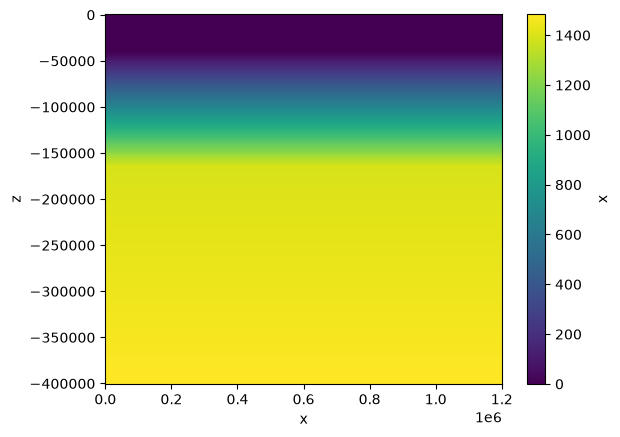

In [ ]:
tempbuild.temperature = xr.where(tempbuild.temperature < 0, 0.0,tempbuild.temperature)
tempbuild.temperature = xr.where(tempbuild.temperature>temp_adiabatic,temp_adiabatic,tempbuild.temperature)

tempbuild.temperature.plot()
tempbuild.temperature[:,j].plot(y='z')